# **1. Import Library dan Menampilkan Informasi Dataset**
Kode ini digunakan untuk mengimpor library yang diperlukan dalam proses analisis data, yaitu Pandas untuk mengolah data, NumPy untuk operasi numerik, dan Matplotlib untuk membuat visualisasi. Selanjutnya, kode menampilkan ukuran dataset, daftar nama kolom, serta lima data pertama untuk mengetahui struktur dan isi dataset sebelum dilakukan analisis lebih lanjut.

In [31]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Menampilkan informasi dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan 5 data pertama
df.head()


Ukuran dataset: (15000, 15)

Nama kolom:
['ID_Karyawan', 'Usia', 'Jenis_Kelamin', 'Peran_Pekerjaan', 'Pendapatan_Bulanan', 'Kepuasan_Kerja', 'Keseimbangan_Kerja_Hidup', 'Jarak_Dari_Rumah_KM', 'Jumlah_Proyek', 'Rata_Rata_Jam_Kerja_Bulanan', 'Lama_Bekerja_Tahun', 'Tahun_Sejak_Promosi_Terakhir', 'Jumlah_Pelatihan_Tahun_Lalu', 'Tingkat_Pendidikan', 'Tingkat_Risiko_Atrisi']


,ID_Karyawan,Usia,Jenis_Kelamin,Peran_Pekerjaan,Pendapatan_Bulanan,Kepuasan_Kerja,Keseimbangan_Kerja_Hidup,Jarak_Dari_Rumah_KM,Jumlah_Proyek,Rata_Rata_Jam_Kerja_Bulanan,Lama_Bekerja_Tahun,Tahun_Sejak_Promosi_Terakhir,Jumlah_Pelatihan_Tahun_Lalu,Tingkat_Pendidikan,Tingkat_Risiko_Atrisi
0,EMP-00001,28,Laki-Laki,Manajer,5873,2,4,20.5,5,193.6,4,4,2,2,1
1,EMP-00002,45,Laki-Laki,Ilmuwan Data,11651,3,2,3.3,2,170.1,5,4,2,3,1
2,EMP-00003,44,Perempuan,Insinyur Perangkat Lunak,8936,4,3,17.3,8,164.4,6,3,6,1,0
3,EMP-00004,22,Perempuan,Ilmuwan Data,6861,3,3,3.8,6,178.3,0,0,0,3,0
4,EMP-00005,23,Perempuan,Ilmuwan Data,6209,4,1,5.6,6,130.4,1,0,3,5,0


# **2. Penyesuaian dan Identifikasi Nama Kolom Dataset**
Kode ini digunakan untuk menyesuaikan nama kolom dataset dalam bahasa Indonesia maupun bahasa Inggris. Fungsi cari_kolom() mencari nama kolom yang sesuai dengan data yang tersedia. Selanjutnya, program menampilkan nama kolom yang ditemukan untuk delapan aspek karyawan, sehingga memudahkan proses visualisasi dan analisis data.

In [32]:
# Menyesuaikan nama kolom bahasa Indonesia dan bahasa Inggris
kolom = {
    "peran": ["Job_Role", "JobRole", "Peran_Pekerjaan"],
    "gender": ["Gender", "Jenis_Kelamin"],
    "atrisi": ["Attrition", "Tingkat_Risiko_Atrisi"],
    "lembur": ["OverTime", "Lembur"],
    "perjalanan": ["BusinessTravel", "Perjalanan_Bisnis"],
    "departemen": ["Department", "Departemen"],
    "pernikahan": ["MaritalStatus", "Status_Pernikahan"],
    "kepuasan": ["JobSatisfaction", "Kepuasan_Kerja"]
}

def cari_kolom(daftar_nama):
    for nama in daftar_nama:
        if nama in df.columns:
            return nama
    return None

peran = cari_kolom(kolom["peran"])
gender = cari_kolom(kolom["gender"])
atrisi = cari_kolom(kolom["atrisi"])
lembur = cari_kolom(kolom["lembur"])
perjalanan = cari_kolom(kolom["perjalanan"])
departemen = cari_kolom(kolom["departemen"])
pernikahan = cari_kolom(kolom["pernikahan"])
kepuasan = cari_kolom(kolom["kepuasan"])

print("Kolom peran pekerjaan:", peran)
print("Kolom jenis kelamin:", gender)
print("Kolom attrition:", atrisi)
print("Kolom lembur:", lembur)
print("Kolom perjalanan bisnis:", perjalanan)
print("Kolom departemen:", departemen)
print("Kolom status pernikahan:", pernikahan)
print("Kolom kepuasan kerja:", kepuasan)


Kolom peran pekerjaan: Peran_Pekerjaan
Kolom jenis kelamin: Jenis_Kelamin
Kolom attrition: Tingkat_Risiko_Atrisi
Kolom lembur: None
Kolom perjalanan bisnis: None
Kolom departemen: None
Kolom status pernikahan: None
Kolom kepuasan kerja: Kepuasan_Kerja


# **3. Visualisasi Distribusi Peran Pekerjaan Karyawan**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan pada setiap peran pekerjaan menggunakan grafik batang (bar chart). Nilai kosong diabaikan, dan jumlah karyawan ditampilkan di atas setiap batang agar mudah dibaca. Grafik ini membantu mengetahui peran pekerjaan dengan jumlah karyawan terbanyak dan paling sedikit.

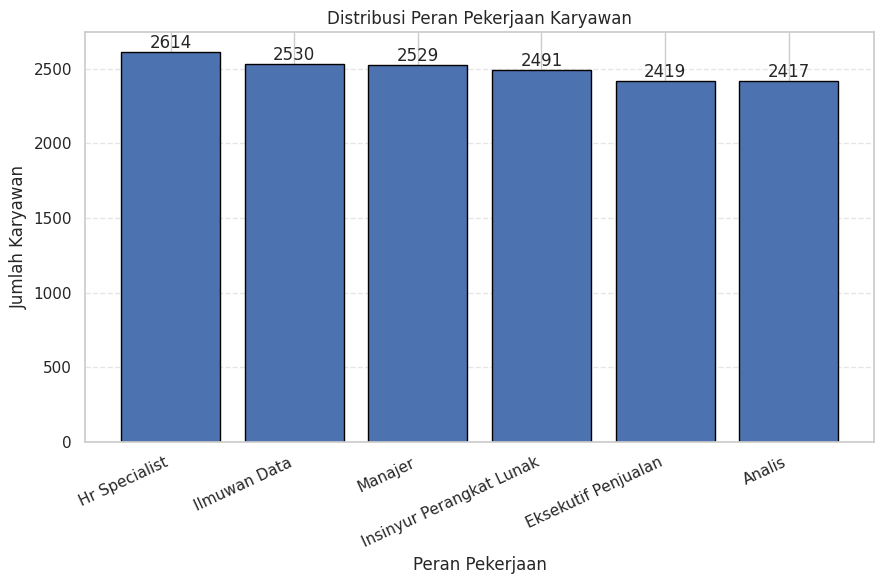

In [33]:
# Menghitung jumlah karyawan pada setiap peran pekerjaan
if peran is not None:
    jumlah_peran = df[peran].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_peran.index.astype(str),
        jumlah_peran.values,
        edgecolor="black"
    )

    plt.title("Distribusi Peran Pekerjaan Karyawan")
    plt.xlabel("Peran Pekerjaan")
    plt.ylabel("Jumlah Karyawan")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom Job Role tidak ditemukan.")


# **4. Visualisasi Distribusi Jenis Kelamin Karyawan**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan berdasarkan jenis kelamin dalam bentuk grafik batang (bar chart). Grafik menampilkan jumlah setiap kategori jenis kelamin, dengan angka di atas batang agar informasi mudah dibaca. Visualisasi ini membantu mengetahui perbandingan jumlah karyawan berdasarkan jenis kelamin.

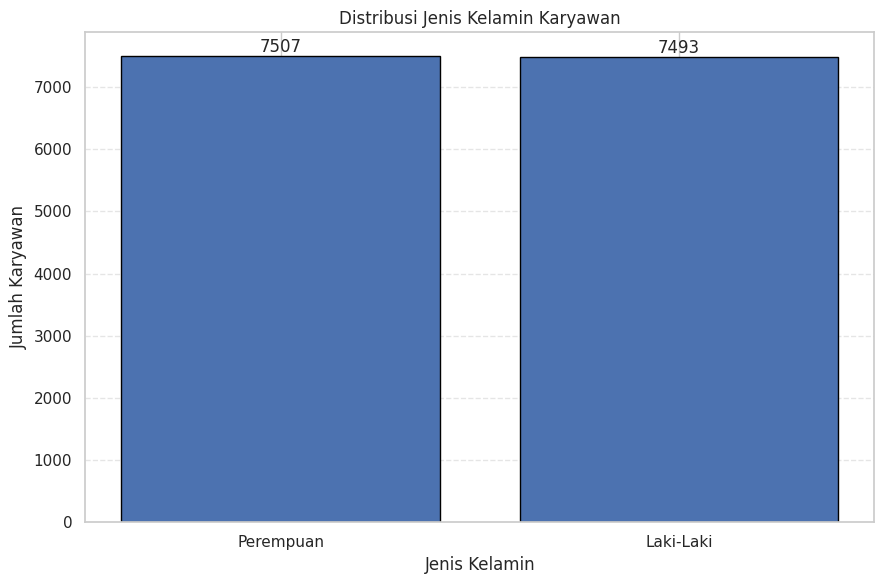

In [34]:
# Menghitung jumlah karyawan berdasarkan jenis kelamin
if gender is not None:
    jumlah_gender = df[gender].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_gender.index.astype(str),
        jumlah_gender.values,
        edgecolor="black"
    )

    plt.title("Distribusi Jenis Kelamin Karyawan")
    plt.xlabel("Jenis Kelamin")
    plt.ylabel("Jumlah Karyawan")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom Gender tidak ditemukan.")


# **5. Visualisasi Distribusi Status Attrition Karyawan**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan berdasarkan status attrition, yaitu karyawan yang keluar atau tetap bekerja di perusahaan. Hasilnya disajikan dalam grafik batang dengan jumlah pada setiap kategori ditampilkan di atas batang. Visualisasi ini membantu melihat perbandingan jumlah karyawan yang keluar dan bertahan di perusahaan.

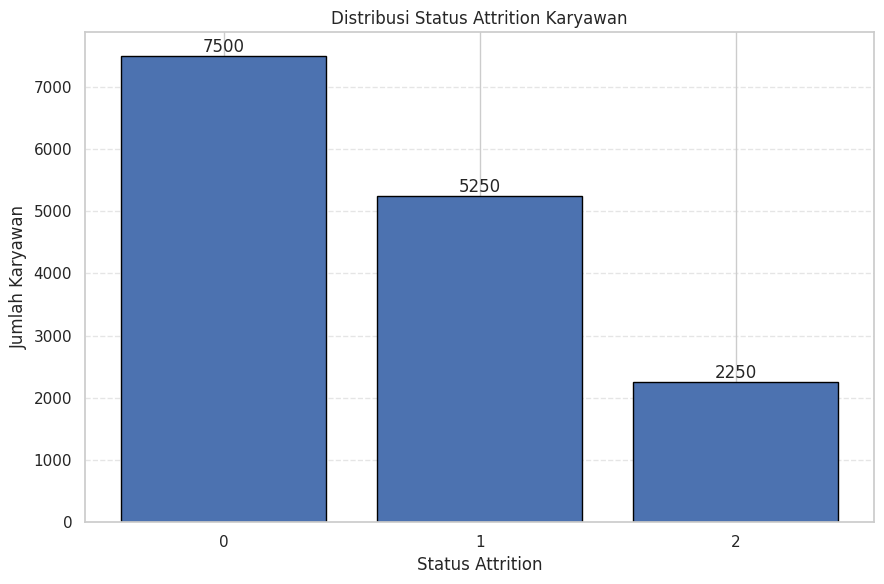

In [35]:
# Menghitung jumlah karyawan berdasarkan status attrition
if atrisi is not None:
    jumlah_atrisi = df[atrisi].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_atrisi.index.astype(str),
        jumlah_atrisi.values,
        edgecolor="black"
    )

    plt.title("Distribusi Status Attrition Karyawan")
    plt.xlabel("Status Attrition")
    plt.ylabel("Jumlah Karyawan")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom Attrition tidak ditemukan.")


# **6. Visualisasi Distribusi Lembur Karyawan**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan berdasarkan status lembur (overtime), yaitu karyawan yang melakukan lembur dan yang tidak. Data divisualisasikan menggunakan grafik batang dengan jumlah pada setiap kategori ditampilkan di atas batang. Grafik ini membantu melihat perbandingan jumlah karyawan berdasarkan status lembur.

In [36]:
# Menghitung jumlah karyawan berdasarkan status lembur
if lembur is not None:
    jumlah_lembur = df[lembur].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_lembur.index.astype(str),
        jumlah_lembur.values,
        edgecolor="black"
    )

    plt.title("Distribusi Lembur Karyawan")
    plt.xlabel("Status Lembur")
    plt.ylabel("Jumlah Karyawan")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom OverTime tidak ditemukan.")


Kolom OverTime tidak ditemukan.


# **7. Visualisasi Distribusi Perjalanan Bisnis Karyawan**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan berdasarkan kategori perjalanan bisnis (Business Travel). Data disajikan dalam bentuk grafik batang, dengan angka jumlah karyawan ditampilkan di atas setiap batang. Visualisasi ini membantu mengetahui kategori perjalanan bisnis yang paling banyak dilakukan oleh karyawan.

In [37]:
# Menghitung jumlah karyawan berdasarkan perjalanan bisnis
if perjalanan is not None:
    jumlah_perjalanan = df[perjalanan].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_perjalanan.index.astype(str),
        jumlah_perjalanan.values,
        edgecolor="black"
    )

    plt.title("Distribusi Perjalanan Bisnis Karyawan")
    plt.xlabel("Kategori Perjalanan Bisnis")
    plt.ylabel("Jumlah Karyawan")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom BusinessTravel tidak ditemukan.")


Kolom BusinessTravel tidak ditemukan.


# **8. Visualisasi Distribusi Karyawan Berdasarkan Departemen**
Kode ini digunakan untuk menghitung dan menampilkan jumlah karyawan pada setiap departemen menggunakan grafik batang (bar chart). Jumlah karyawan ditampilkan di atas setiap batang agar mudah dibaca. Visualisasi ini membantu mengetahui departemen dengan jumlah karyawan terbanyak dan paling sedikit.

In [38]:
# Menghitung jumlah karyawan pada setiap departemen
if departemen is not None:
    jumlah_departemen = df[departemen].dropna().value_counts()

    plt.figure(figsize=(9, 6))
    bars = plt.bar(
        jumlah_departemen.index.astype(str),
        jumlah_departemen.values,
        edgecolor="black"
    )

    plt.title("Distribusi Karyawan Berdasarkan Departemen")
    plt.xlabel("Departemen")
    plt.ylabel("Jumlah Karyawan")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    for bar in bars:
        tinggi = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{int(tinggi)}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("Kolom Department tidak ditemukan.")


Kolom Department tidak ditemukan.


# **Kesimpulan**

Berdasarkan hasil visualisasi data karyawan, grafik batang memudahkan pemahaman distribusi karyawan berdasarkan delapan aspek, seperti peran pekerjaan, jenis kelamin, atrisi, lembur, departemen, dan kepuasan kerja. Visualisasi ini membantu mengidentifikasi kategori dengan jumlah karyawan terbanyak dan paling sedikit serta menjadi bahan evaluasi untuk mendukung pengambilan keputusan dalam pengelolaan sumber daya manusia.